# Задание 9. Разделяющая кривая

## Imports

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [10, 6]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

## Решение

In [25]:
np.seterr(over='ignore')
rs = np.random.RandomState(42)
theta = rs.uniform(-1, 1, size=29)
theta

array([-0.25091976,  0.90142861,  0.46398788,  0.19731697, -0.68796272,
       -0.68801096, -0.88383278,  0.73235229,  0.20223002,  0.41614516,
       -0.95883101,  0.9398197 ,  0.66488528, -0.57532178, -0.63635007,
       -0.63319098, -0.39151551,  0.04951286, -0.13610996, -0.41754172,
        0.22370579, -0.72101228, -0.4157107 , -0.26727631, -0.08786003,
        0.57035192, -0.60065244,  0.02846888,  0.18482914])

In [32]:
def z_val(x, y, theta):
    return (
        theta[0] +
        theta[1] * x + theta[2] * y + 
        theta[3] * x * y + theta[4] * x**2 + theta[5] * y**2 +
        theta[6] * x**2 * y + theta[7] * x * y**2 + theta[8] * x**3 + theta[9] * y**3 +
        theta[10] * x * y**3 + theta[11] * x**3 * y + theta[12] * x**2 * y**2 + theta[13] * x**4 + theta[14] * y**4 +
        theta[15] * x * y**4 + theta[16] * x**4 * y + theta[17] * x**2 * y**3 + theta[18] * x**3 * y**2 +
        theta[19] * x**5 + theta[20] * y**5 +
        theta[21] * x * y**5 + theta[22] * x**5 * y + theta[23] * x**2 * y**4 + theta[24] * x**4 * y**2 +
        theta[25] * x**3 * y**3 + theta[26] * x**6 + theta[27] * y**6 + theta[28] * x**7
    )

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

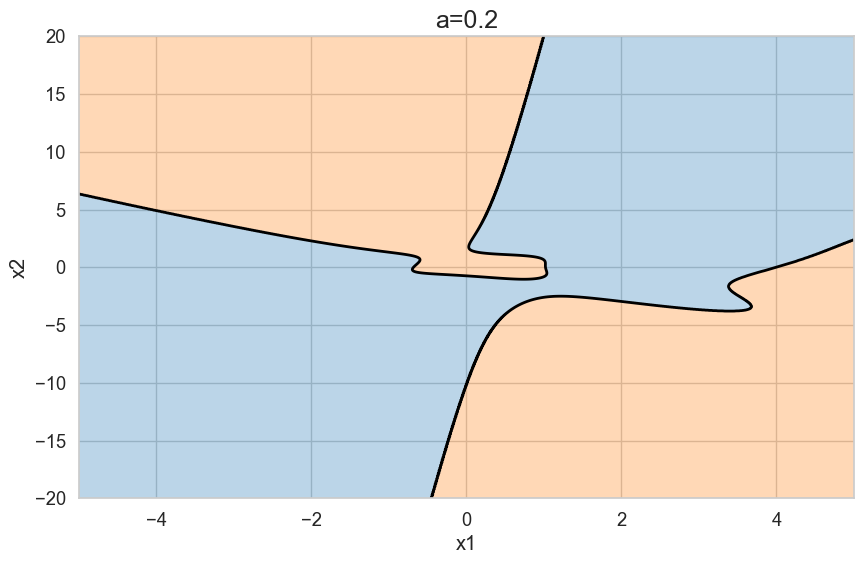

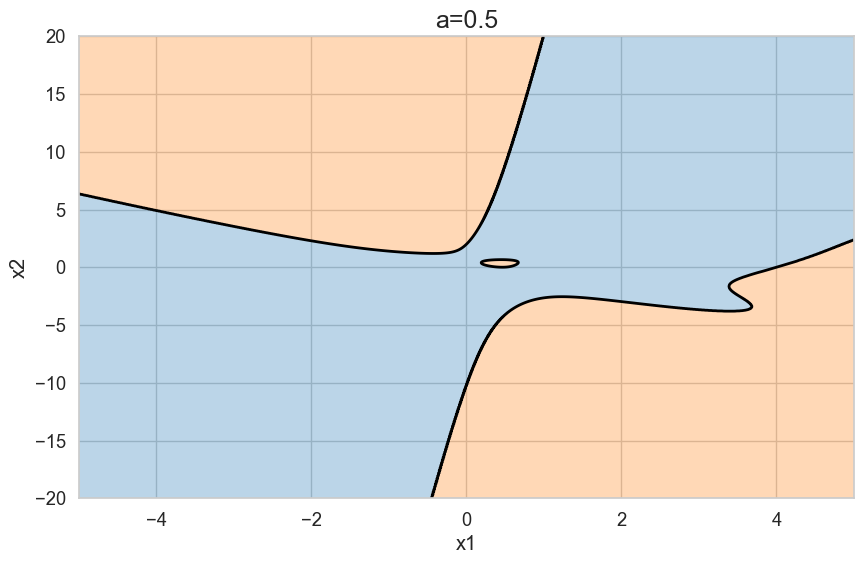

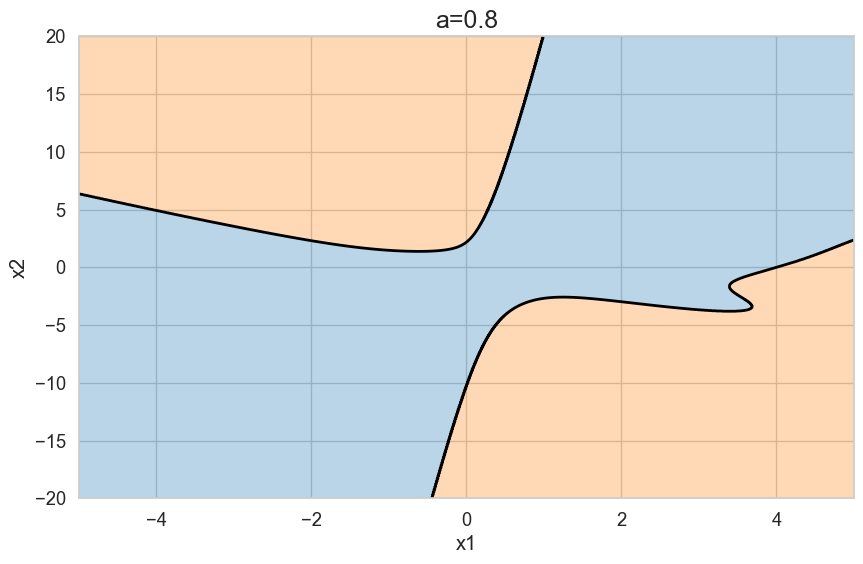

In [33]:
xs = np.linspace(-5, 5, 1000)

x1_values = np.linspace(-5, 5, 1000)
x2_values = np.linspace(-20, 20, 2000)

X1, X2 = np.meshgrid(x1_values, x2_values)
Z = z_val(X1, X2, theta)
H = sigmoid(Z)

for a in [0.2, 0.5, 0.8]:
    plt.contourf(X1, X2, H, levels=[0, a, 1], colors=["C0", "C1"], alpha=0.3)
    plt.contour(X1, X2, H, levels=[a], colors='black', linewidths=2)
    plt.xlim(-5, 5)
    plt.ylim(-20, 20)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"a={a}", fontsize=18)
    plt.show()

In [38]:
print("=== Пробные точки ===\n")

points_to_check = [(-4, 0), (-2, 15)]
a = 0.5
for pnt in points_to_check:
    print(f"Точка: {pnt}")
    x1, x2 = pnt
    z = z_val(x1, x2, theta)
    h = sigmoid(z)
    sign = ">" if h > a else "<"
    bin_class = 1 if h > a else 0
    print(f"h(z) {sign} a ==> Класс {bin_class}\n")

=== Пробные точки ===

Точка: (-4, 0)
h(z) < a ==> Класс 0

Точка: (-2, 15)
h(z) > a ==> Класс 1



In [45]:
def z_val_by_a(a):
    return np.log(a / (1 - a))

for a in [0.2, 0.5, 0.8]:
    print(f"Порог a = {a}: разрез по z = {z_val_by_a(a):.2f}")

Порог a = 0.2: разрез по z = -1.39
Порог a = 0.5: разрез по z = 0.00
Порог a = 0.8: разрез по z = 1.39


## 3D-график

<IPython.core.display.Javascript object>


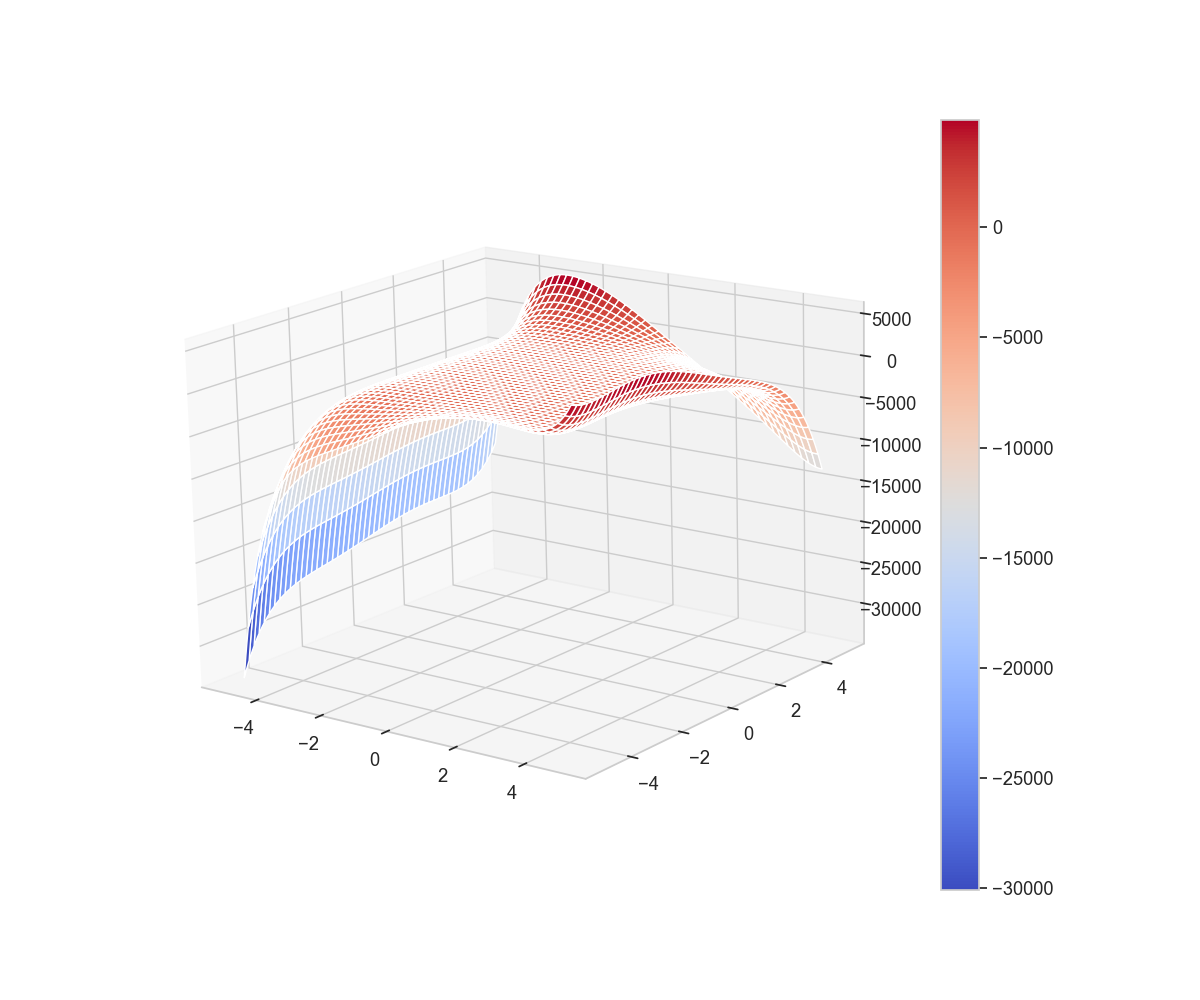

In [56]:
lim = 5
x1_values = np.linspace(-lim, lim, 500)
x2_values = np.linspace(-lim, lim, 500)
X1, X2 = np.meshgrid(x1_values, x2_values)

Z = z_val(X1, X2, theta)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X1, X2, Z, cmap="coolwarm")
fig.colorbar(surf)
plt.show()